# Lab Exercise: Generative Adversarial Networks

**Dataset:** MVTec AD — Bottle  

**Framework:** TensorFlow / Keras  

**Author:** Maritza Elizabeth Albán Escobar  

## Objective

The objective of this laboratory is to develop and evaluate a Generative Adversarial Network (GAN) for image generation and anomaly detection using the MVTec AD dataset.

The laboratory includes the following objectives:

1. **Build a Generator** capable of producing synthetic bottle images from random latent vectors.

2. **Build a Discriminator** as a binary classifier to distinguish real images from generated images.

3. **Train the GAN** by alternately optimizing the Discriminator and Generator through adversarial learning.

4. **Evaluate the trained Discriminator** as a potential anomaly detector using real test images containing defect-free and defective bottles.

5. **Analyze the generated images and discriminator scores** to investigate the relationship between image generation, adversarial learning, and anomaly detection.

# 1. Dataset

The MVTec AD Bottle category is used in this laboratory to investigate image generation and anomaly detection.

The Generator is trained using defect-free bottle images as real samples, while the Discriminator learns to distinguish real images from generated images. The test set contains both defect-free images and images with different types of defects, which are used to evaluate the Discriminator as a potential anomaly detector.

In [ ]:
# ==========================================
# 1.1 IMPORT LIBRARIES AND MOUNT GOOGLE DRIVE
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models

# Mount Google Drive
from pathlib import Path

# Display TensorFlow version
print("TensorFlow version:", tf.__version__)

# ==========================================
# 1.2 DEFINE DATASET PATH AND PARAMETERS
# ==========================================

DATA_DIR = Path("bottle")

IMG_SIZE = (128, 128)
CHANNELS = 3
BATCH_SIZE = 16

print("Dataset path:", DATA_DIR)

# ==========================================
# 1.3 LOAD REAL TRAINING IMAGES
# ==========================================

TRAIN_DIR = DATA_DIR / "train" / "good"

train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

print("Training directory:", TRAIN_DIR)
print("Number of batches:", tf.data.experimental.cardinality(train_dataset).numpy())

# ==========================================
# 1.4 NORMALIZE REAL IMAGES
# ==========================================

def normalize_images(images):
    images = tf.cast(images, tf.float32) / 255.0
    return images

train_dataset = train_dataset.map( normalize_images,num_parallel_calls=tf.data.AUTOTUNE)

train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)



I0000 00:00:1792081604.467738   82953 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792081605.087871   82953 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792081608.408149   82953 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0
Dataset path: bottle
Found 209 files.


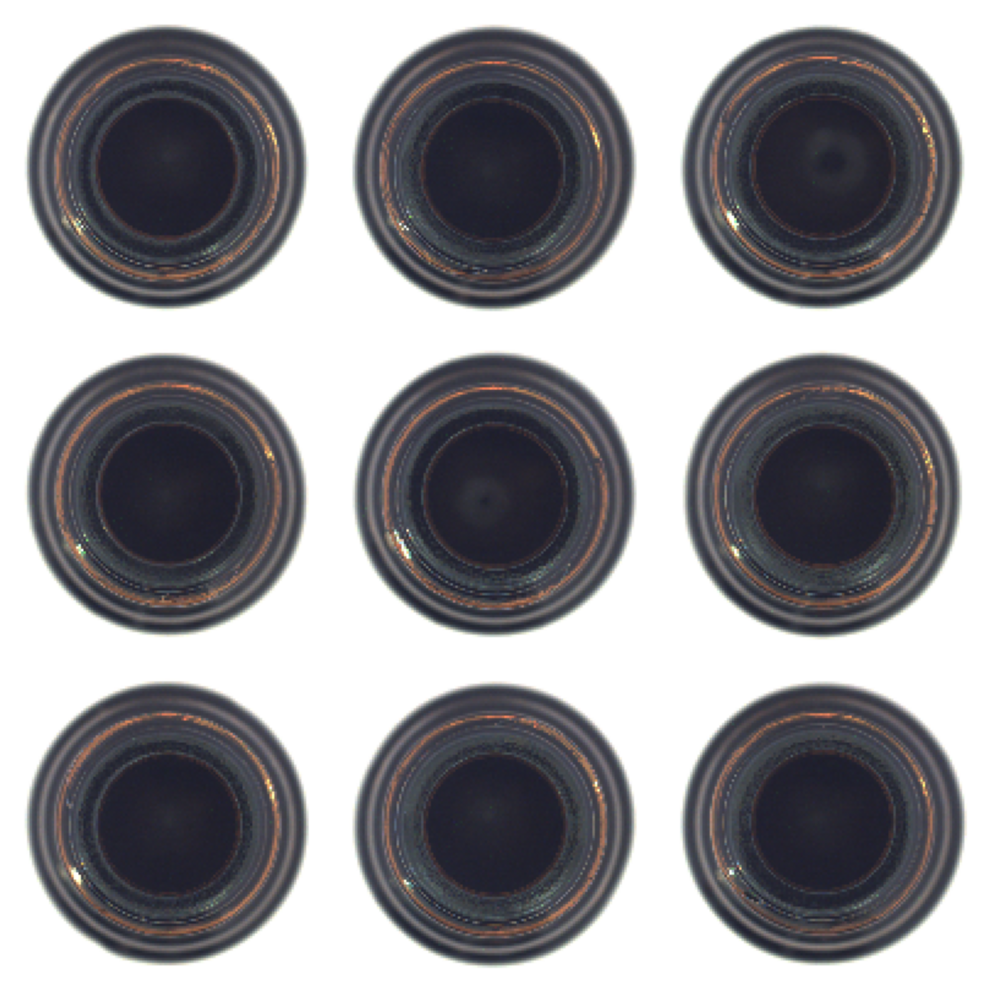

In [ ]:
# ==========================================
# 1.5 VISUALIZE REAL IMAGES
# ==========================================

for images in train_dataset.take(1):
    plt.figure(figsize=(10, 10))

    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.axis("off")

    plt.tight_layout()
    plt.show()

### Dataset Analysis

The training dataset contains 209 defect-free bottle images organized into 14 batches. The images are resized to 128 × 128 pixels and normalized to the [0, 1] range, providing a consistent representation for the real samples used during adversarial training.

The visual inspection confirms that the training images represent defect-free bottles with consistent image dimensions and appearance. These images will be used as the real samples for training the Discriminator.

# 2. Generator

The Generator learns to transform random latent vectors into synthetic bottle images. Its architecture progressively increases the spatial resolution of the latent representation until reaching the target image size of 128 × 128 × 3.

In [ ]:
# ==========================================
# 2.1 DEFINE GENERATOR PARAMETERS
# ==========================================

LATENT_DIM = 128

print("Latent vector dimension:", LATENT_DIM)
print("Generator output shape:", (*IMG_SIZE, CHANNELS))

# ==========================================
# 2.2 BUILD THE GENERATOR
# ==========================================

generator = models.Sequential(name="Generator")

generator.add(layers.Input(shape=(LATENT_DIM,)))

# Project latent vector into a spatial representation
generator.add(layers.Dense(16 * 16 * 128))
generator.add(layers.Reshape((16, 16, 128)))

# Upsampling: 16x16 -> 32x32
generator.add(layers.Conv2DTranspose(
    64, kernel_size=4, strides=2, padding="same"
))
generator.add(layers.BatchNormalization())
generator.add(layers.ReLU())

# Upsampling: 32x32 -> 64x64
generator.add(layers.Conv2DTranspose(
    32, kernel_size=4, strides=2, padding="same"
))
generator.add(layers.BatchNormalization())
generator.add(layers.ReLU())

# Upsampling: 64x64 -> 128x128
generator.add(layers.Conv2DTranspose(
    16, kernel_size=4, strides=2, padding="same"
))
generator.add(layers.BatchNormalization())
generator.add(layers.ReLU())

# RGB output
generator.add(layers.Conv2D(
    CHANNELS,
    kernel_size=3,
    padding="same",
    activation="sigmoid"
))

generator.summary()

Latent vector dimension: 128
Generator output shape: (128, 128, 3)


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32768)          │     4,227,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 32, 32, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 64, 64, 32)     │        32,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 128, 128, 16)   │         8,208 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 3)    │           435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,400,099 (16.79 MB)

 Trainable params: 4,399,875 (16.78 MB)

 Non-trainable params: 224 (896.00 B)

I0000 00:00:1792078944.647384   71464 cuda_dnn.cc:461] Loaded cuDNN version 92700


Latent vector shape: (1, 128)
Generated image shape: (1, 128, 128, 3)
Pixel range: 0.4940338730812073 to 0.5087400078773499


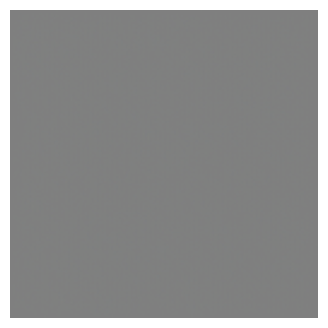

In [ ]:
# ==========================================
# 2.3 GENERATE AN UNTRAINED IMAGE
# ==========================================

z = tf.random.normal((1, LATENT_DIM))

generated_image = generator(z, training=False)

print("Latent vector shape:", z.shape)
print("Generated image shape:", generated_image.shape)
print(
    "Pixel range:",
    float(tf.reduce_min(generated_image)),
    "to",
    float(tf.reduce_max(generated_image))
)

# ==========================================
# 2.4 VISUALIZE UNTRAINED OUTPUT
# ==========================================

plt.figure(figsize=(4, 4))
plt.imshow(generated_image[0])
plt.axis("off")
plt.show()

###Generator Analysis

The Generator receives a 128-dimensional random latent vector and transforms it into a 128 × 128 × 3 RGB image through a sequence of learned layers. Before training, the generated output does not contain meaningful bottle structures, as the network weights have not yet learned the characteristics of the real dataset. The sigmoid output constrains the generated pixel values to the [0, 1] range.

#3. Discriminator

The Discriminator is a convolutional binary classifier that learns to distinguish real bottle images from images generated by the Generator. It receives an RGB image of size 128 × 128 and produces a single realness score in the [0, 1] range.

In [ ]:
# ==========================================
# 3.1 BUILD THE DISCRIMINATOR
# ==========================================

discriminator = models.Sequential(name="Discriminator")

discriminator.add(layers.Input(
    shape=(*IMG_SIZE, CHANNELS)
))

# Feature extraction
discriminator.add(layers.Conv2D(
    32, kernel_size=4, strides=2, padding="same"
))
discriminator.add(layers.LeakyReLU(negative_slope=0.2))

discriminator.add(layers.Conv2D(
    64, kernel_size=4, strides=2, padding="same"
))
discriminator.add(layers.BatchNormalization())
discriminator.add(layers.LeakyReLU(negative_slope=0.2))

discriminator.add(layers.Conv2D(
    128, kernel_size=4, strides=2, padding="same"
))
discriminator.add(layers.BatchNormalization())
discriminator.add(layers.LeakyReLU(negative_slope=0.2))

# Classification
discriminator.add(layers.Flatten())
discriminator.add(layers.Dense(1, activation="sigmoid"))

discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        32,769 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 199,137 (777.88 KB)

 Trainable params: 198,753 (776.38 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
# ==========================================
# 3.2 TEST THE UNTRAINED DISCRIMINATOR
# ==========================================

# Get one real image
real_images = next(iter(train_dataset))
real_image = real_images[:1]

# Generate one fake image
z = tf.random.normal((1, LATENT_DIM))
fake_image = generator(z, training=False)

# Discriminator predictions
real_score = discriminator(real_image, training=False)
fake_score = discriminator(fake_image, training=False)

print("Real image score:", float(real_score[0, 0]))
print("Generated image score:", float(fake_score[0, 0]))

# ==========================================
# 3.3 COMPILE THE DISCRIMINATOR
# ==========================================

discriminator.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

Real image score: 0.4253513813018799
Generated image score: 0.4364106059074402


###Discriminator Analysis

The Discriminator is implemented as a convolutional binary classifier that maps a 128 × 128 × 3 image to a single realness score. Convolutional layers extract visual features while the final sigmoid activation converts the classification output into a value between 0 and 1. Before training, the predictions do not yet represent reliable real/fake discrimination because the network has not learned from the dataset.

#GAN Architecture

The Generator and Discriminator are connected to form the adversarial architecture. The Generator receives a latent vector and produces a synthetic image, which is then evaluated by the Discriminator. This combined model allows the Generator to receive feedback from the Discriminator during training.

In [ ]:
# ==========================================
# 4.1 CONNECT GENERATOR AND DISCRIMINATOR
# ==========================================

discriminator.trainable = False

gan = models.Sequential(
    [generator, discriminator],
    name="GAN"
)

gan.summary()


Model: "GAN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Generator (Sequential)          │ (None, 128, 128, 3)    │     4,400,099 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       199,137 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,599,236 (17.54 MB)

 Trainable params: 4,399,875 (16.78 MB)

 Non-trainable params: 199,361 (778.75 KB)

In [ ]:
# ==========================================
# 4.2 COMPILE THE GAN
# ==========================================

gan.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002),
    loss="binary_crossentropy"
)

gan.summary()

Model: "GAN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Generator (Sequential)          │ (None, 128, 128, 3)    │     4,400,099 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       199,137 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,599,236 (17.54 MB)

 Trainable params: 4,399,875 (16.78 MB)

 Non-trainable params: 199,361 (778.75 KB)

In [ ]:
# ==========================================
# 4.3 TEST THE COMBINED GAN
# ==========================================

z = tf.random.normal((1, LATENT_DIM))

gan_output = gan(z, training=False)

print("Latent vector shape:", z.shape)
print("GAN output shape:", gan_output.shape)
print("Discriminator score:", float(gan_output[0, 0]))

Latent vector shape: (1, 128)
GAN output shape: (1, 1)
Discriminator score: 0.43642354011535645


### GAN Architecture Analysis

The Generator and Discriminator are successfully connected in a single adversarial model. The Generator transforms a latent vector into a synthetic image, while the frozen Discriminator evaluates its realness.

The combined model produces a single discriminator score from each latent vector. Before training, the observed score is close to 0.5, which is expected because the Discriminator has not yet learned to distinguish real and generated images.

The model configuration confirms that the Generator remains trainable while the Discriminator is frozen during Generator optimization. This configuration allows gradients to propagate through the Discriminator while updating only the Generator parameters.



# 5. GAN Training

The GAN is trained through alternating optimization of the Discriminator and Generator. The Discriminator learns to distinguish real images from generated images, while the Generator is optimized to produce images that the Discriminator classifies as real.

In [ ]:
# ==========================================
# 5.1 DEFINE TRAINING PARAMETERS
# ==========================================

EPOCHS = 50

# Fixed latent vectors for monitoring Generator progress
FIXED_Z = tf.random.normal((9, LATENT_DIM))

# Store training history
d_losses = []
d_accuracies = []
g_losses = []

print("Number of epochs:", EPOCHS)
print("Fixed latent vectors shape:", FIXED_Z.shape)

# ==========================================
# 5.2 ADVERSARIAL TRAINING LOOP
# ==========================================

for epoch in range(EPOCHS):

    epoch_d_losses = []
    epoch_d_accuracies = []
    epoch_g_losses = []

    for real_images in train_dataset:

        # Current batch size
        current_batch_size = tf.shape(real_images)[0]

        # ------------------------------------------
        # Train Discriminator
        # ------------------------------------------

        # Generate fake images
        z = tf.random.normal(
            (current_batch_size, LATENT_DIM)
        )

        fake_images = generator(
            z,
            training=True
        )

        # Labels:
        # Real images -> 1
        # Fake images -> 0
        real_labels = tf.ones(
            (current_batch_size, 1)
        )

        fake_labels = tf.zeros(
            (current_batch_size, 1)
        )

        # Combine real and fake samples
        combined_images = tf.concat(
            [real_images, fake_images],
            axis=0
        )

        combined_labels = tf.concat(
            [real_labels, fake_labels],
            axis=0
        )

        # Enable Discriminator training
        discriminator.trainable = True

        d_loss, d_accuracy = discriminator.train_on_batch(
            combined_images,
            combined_labels
        )

        # ------------------------------------------
        # Train Generator
        # ------------------------------------------

        # Freeze Discriminator weights
        discriminator.trainable = False

        # Generate a new batch of latent vectors
        z = tf.random.normal(
            (current_batch_size, LATENT_DIM)
        )

        # Generator target is 1:
        # it wants the Discriminator to classify
        # generated images as real
        generator_targets = tf.ones(
            (current_batch_size, 1)
        )

        g_loss = gan.train_on_batch(
            z,
            generator_targets
        )

        # Store batch results
        epoch_d_losses.append(float(d_loss))
        epoch_d_accuracies.append(float(d_accuracy))
        epoch_g_losses.append(float(g_loss))

    # Average results for the epoch
    mean_d_loss = np.mean(epoch_d_losses)
    mean_d_accuracy = np.mean(epoch_d_accuracies)
    mean_g_loss = np.mean(epoch_g_losses)

    d_losses.append(mean_d_loss)
    d_accuracies.append(mean_d_accuracy)
    g_losses.append(mean_g_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"D Loss: {mean_d_loss:.4f} | "
        f"D Acc: {mean_d_accuracy:.4f} | "
        f"G Loss: {mean_g_loss:.4f}"
    )

Number of epochs: 50
Fixed latent vectors shape: (9, 128)


I0000 00:00:1792078950.201220   71464 service.cc:153] XLA service 0x2d613e00 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792078950.201256   71464 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5060 Laptop GPU, Compute Capability 12.0a (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792078950.346548   71464 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792078954.557317   71464 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1792078956.710252   71464 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_6491__XlaMustCompile_true_config_proto_2201667018877855759_executor_type_11160318154034397263_.28
I0000 00:00:1792078958.778106   72113 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to loca

Epoch 01/50 | D Loss: 0.1893 | D Acc: 0.9598 | G Loss: 0.8355
Epoch 02/50 | D Loss: 0.0026 | D Acc: 1.0000 | G Loss: 0.8619
Epoch 03/50 | D Loss: 0.0037 | D Acc: 1.0000 | G Loss: 0.9803
Epoch 04/50 | D Loss: 0.0045 | D Acc: 1.0000 | G Loss: 1.2217
Epoch 05/50 | D Loss: 0.0041 | D Acc: 1.0000 | G Loss: 1.5443
Epoch 06/50 | D Loss: 0.0022 | D Acc: 1.0000 | G Loss: 2.2132
Epoch 07/50 | D Loss: 0.0035 | D Acc: 0.9978 | G Loss: 2.8278
Epoch 08/50 | D Loss: 0.0009 | D Acc: 1.0000 | G Loss: 3.3584
Epoch 09/50 | D Loss: 0.0006 | D Acc: 1.0000 | G Loss: 3.6399
Epoch 10/50 | D Loss: 0.0003 | D Acc: 1.0000 | G Loss: 3.7604
Epoch 11/50 | D Loss: 0.0005 | D Acc: 1.0000 | G Loss: 4.1203
Epoch 12/50 | D Loss: 0.0006 | D Acc: 1.0000 | G Loss: 4.5644
Epoch 13/50 | D Loss: 0.0004 | D Acc: 1.0000 | G Loss: 5.0515
Epoch 14/50 | D Loss: 0.0005 | D Acc: 1.0000 | G Loss: 5.6670
Epoch 15/50 | D Loss: 0.0007 | D Acc: 1.0000 | G Loss: 6.1872
Epoch 16/50 | D Loss: 0.0003 | D Acc: 1.0000 | G Loss: 6.5486
Epoch 17

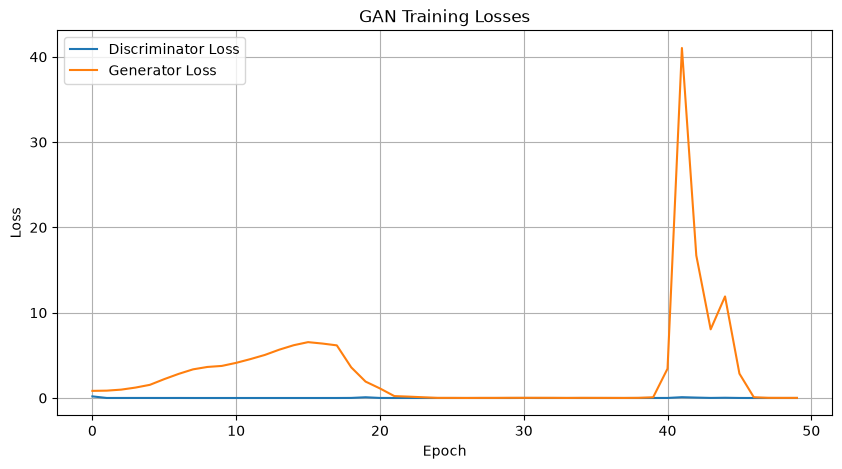

In [ ]:
# ==========================================
# 5.3 PLOT GAN TRAINING LOSSES
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(d_losses, label="Discriminator Loss")
plt.plot(g_losses, label="Generator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Losses")
plt.legend()
plt.grid(True)

plt.show()

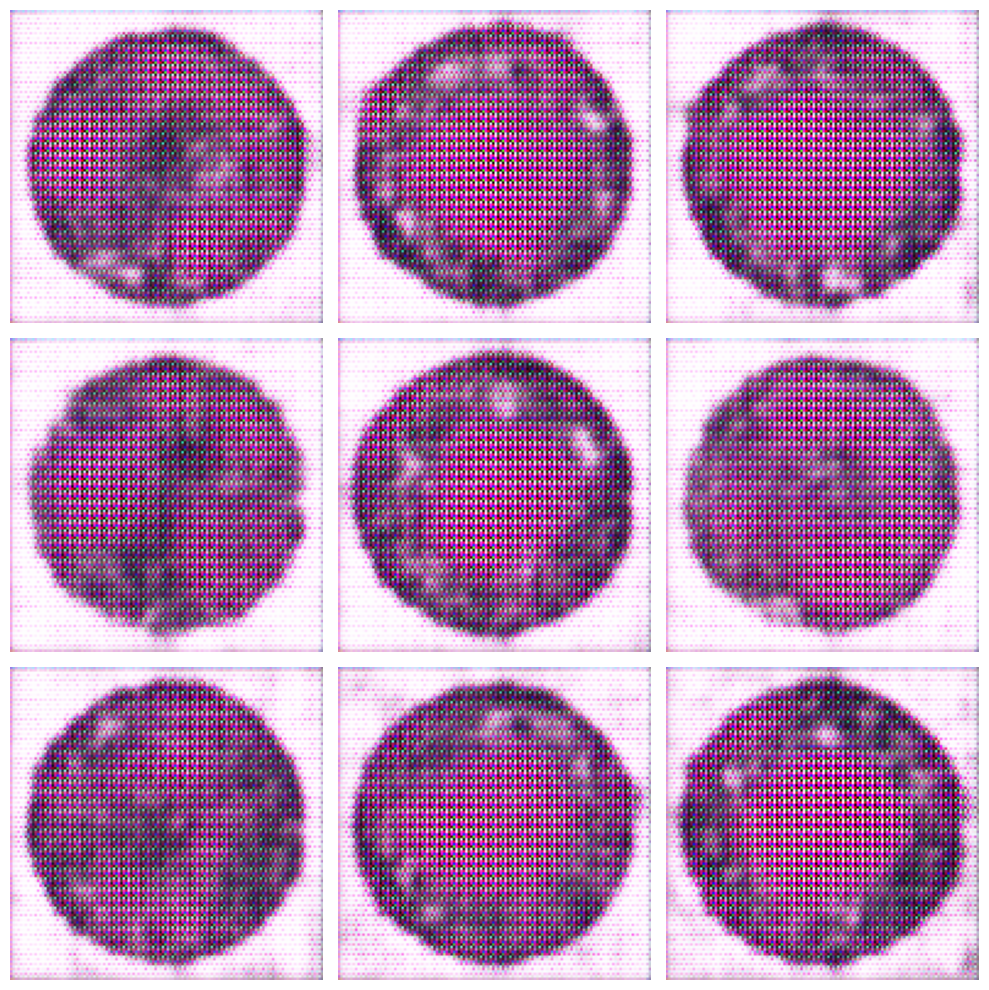

In [ ]:
# ==========================================
# 5.4 VISUALIZE GENERATED IMAGES
# ==========================================

generated_images = generator(
    FIXED_Z,
    training=False
)

plt.figure(figsize=(10, 10))

for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(generated_images[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 5.5 BUILD GENERATOR V2
# ==========================================

generator_v2 = models.Sequential(name="Generator_V2")

generator_v2.add(layers.Input(shape=(LATENT_DIM,)))

# Project latent vector into a rich spatial representation
generator_v2.add(layers.Dense(8 * 8 * 512))
generator_v2.add(layers.Reshape((8, 8, 512)))

# Upsampling: 8x8 -> 16x16
generator_v2.add(layers.UpSampling2D(size=(2, 2)))
generator_v2.add(layers.Conv2D(
    256,
    kernel_size=3,
    padding="same"
))
generator_v2.add(layers.BatchNormalization())
generator_v2.add(layers.ReLU())

# Upsampling: 16x16 -> 32x32
generator_v2.add(layers.UpSampling2D(size=(2, 2)))
generator_v2.add(layers.Conv2D(
    128,
    kernel_size=3,
    padding="same"
))
generator_v2.add(layers.BatchNormalization())
generator_v2.add(layers.ReLU())

# Upsampling: 32x32 -> 64x64
generator_v2.add(layers.UpSampling2D(size=(2, 2)))
generator_v2.add(layers.Conv2D(
    64,
    kernel_size=3,
    padding="same"
))
generator_v2.add(layers.BatchNormalization())
generator_v2.add(layers.ReLU())

# Upsampling: 64x64 -> 128x128
generator_v2.add(layers.UpSampling2D(size=(2, 2)))
generator_v2.add(layers.Conv2D(
    32,
    kernel_size=3,
    padding="same"
))
generator_v2.add(layers.BatchNormalization())
generator_v2.add(layers.ReLU())

# RGB output
generator_v2.add(layers.Conv2D(
    CHANNELS,
    kernel_size=3,
    padding="same",
    activation="sigmoid"
))

generator_v2.summary()

Model: "Generator_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32768)          │     4,227,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 256)    │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 128, 128, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,797,059 (22.11 MB)

 Trainable params: 5,796,099 (22.11 MB)

 Non-trainable params: 960 (3.75 KB)

Latent vector shape: (1, 128)
Generated image shape: (1, 128, 128, 3)
Pixel range: 0.46430182456970215 to 0.5427373647689819


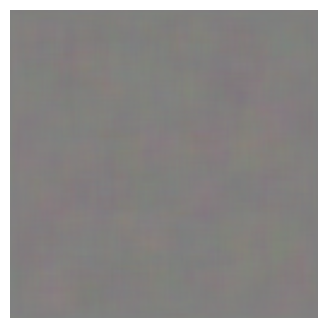

In [ ]:
# ==========================================
# 5.6 TEST UNTRAINED GENERATOR V2
# ==========================================

z = tf.random.normal((1, LATENT_DIM))

generated_image_v2 = generator_v2(
    z,
    training=False
)

print("Latent vector shape:", z.shape)
print("Generated image shape:", generated_image_v2.shape)

print(
    "Pixel range:",
    float(tf.reduce_min(generated_image_v2)),
    "to",
    float(tf.reduce_max(generated_image_v2))
)

# ==========================================
# 5.7 VISUALIZE UNTRAINED GENERATOR V2
# ==========================================

plt.figure(figsize=(4, 4))

plt.imshow(generated_image_v2[0])
plt.axis("off")

plt.show()

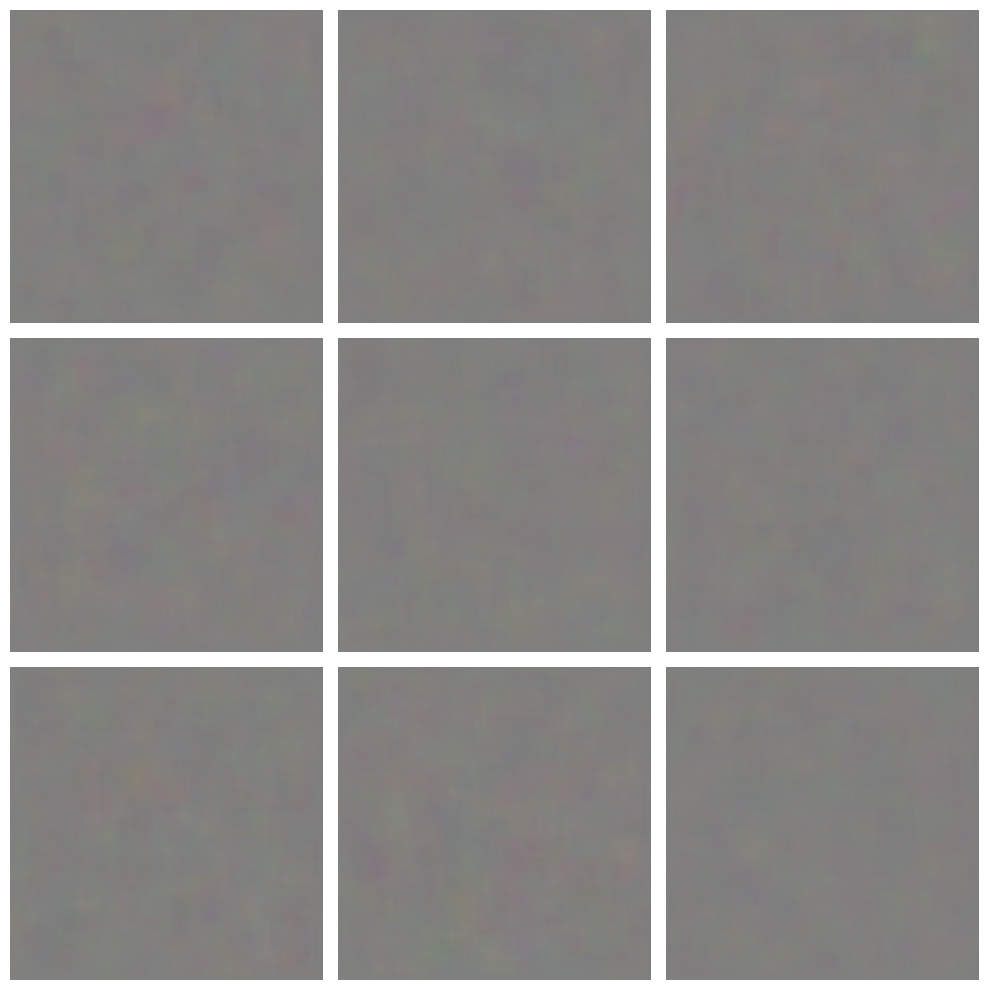

In [ ]:
# ==========================================
# 5.8 TEST GENERATOR V2 WITH MULTIPLE LATENT VECTORS
# ==========================================

z = tf.random.normal((9, LATENT_DIM))

generated_images_v2 = generator_v2(
    z,
    training=False
)

plt.figure(figsize=(10, 10))

for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(generated_images_v2[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 5.9 CONNECT GENERATOR V2 WITH DISCRIMINATOR
# ==========================================

# Freeze the Discriminator for Generator optimization
discriminator.trainable = False

gan_v2 = models.Sequential(
    [generator_v2, discriminator],
    name="GAN_V2"
)

gan_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0002
    ),
    loss="binary_crossentropy"
)

gan_v2.summary()

# ==========================================
# 5.10 TRAIN GAN V2
# ==========================================

EPOCHS_V2 = 50

d_losses_v2 = []
d_accuracies_v2 = []
g_losses_v2 = []

FIXED_Z_V2 = tf.random.normal((9, LATENT_DIM))

for epoch in range(EPOCHS_V2):

    epoch_d_losses = []
    epoch_d_accuracies = []
    epoch_g_losses = []

    for real_images in train_dataset:

        current_batch_size = tf.shape(real_images)[0]

        # ------------------------------------------
        # Train Discriminator
        # ------------------------------------------

        z = tf.random.normal(
            (current_batch_size, LATENT_DIM)
        )

        fake_images = generator_v2(
            z,
            training=True
        )

        real_labels = tf.ones(
            (current_batch_size, 1)
        )

        fake_labels = tf.zeros(
            (current_batch_size, 1)
        )

        combined_images = tf.concat(
            [real_images, fake_images],
            axis=0
        )

        combined_labels = tf.concat(
            [real_labels, fake_labels],
            axis=0
        )

        discriminator.trainable = True

        d_loss, d_accuracy = discriminator.train_on_batch(
            combined_images,
            combined_labels
        )

        # ------------------------------------------
        # Train Generator V2
        # ------------------------------------------

        discriminator.trainable = False

        z = tf.random.normal(
            (current_batch_size, LATENT_DIM)
        )

        generator_targets = tf.ones(
            (current_batch_size, 1)
        )

        g_loss = gan_v2.train_on_batch(
            z,
            generator_targets
        )

        epoch_d_losses.append(float(d_loss))
        epoch_d_accuracies.append(float(d_accuracy))
        epoch_g_losses.append(float(g_loss))

    mean_d_loss = np.mean(epoch_d_losses)
    mean_d_accuracy = np.mean(epoch_d_accuracies)
    mean_g_loss = np.mean(epoch_g_losses)

    d_losses_v2.append(mean_d_loss)
    d_accuracies_v2.append(mean_d_accuracy)
    g_losses_v2.append(mean_g_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS_V2} | "
        f"D Loss: {mean_d_loss:.4f} | "
        f"D Acc: {mean_d_accuracy:.4f} | "
        f"G Loss: {mean_g_loss:.4f}"
    )

Model: "GAN_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Generator_V2 (Sequential)       │ (None, 128, 128, 3)    │     5,797,059 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       199,137 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,996,196 (22.87 MB)

 Trainable params: 5,796,099 (22.11 MB)

 Non-trainable params: 200,097 (781.63 KB)

I0000 00:00:1792079004.222832   71464 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_138599__XlaMustCompile_true_config_proto_2201667018877855759_executor_type_11160318154034397263_.41


Epoch 01/50 | D Loss: 0.0000 | D Acc: 1.0000 | G Loss: 42.7772
Epoch 02/50 | D Loss: 0.0014 | D Acc: 1.0000 | G Loss: 20.6686
Epoch 03/50 | D Loss: 0.0023 | D Acc: 1.0000 | G Loss: 13.6974
Epoch 04/50 | D Loss: 0.0032 | D Acc: 1.0000 | G Loss: 10.4388
Epoch 05/50 | D Loss: 0.0027 | D Acc: 1.0000 | G Loss: 7.4622
Epoch 06/50 | D Loss: 0.0019 | D Acc: 1.0000 | G Loss: 5.3859
Epoch 07/50 | D Loss: 0.0040 | D Acc: 1.0000 | G Loss: 3.5178
Epoch 08/50 | D Loss: 0.0302 | D Acc: 1.0000 | G Loss: 3.1249
Epoch 09/50 | D Loss: 0.2987 | D Acc: 0.9174 | G Loss: 6.7291
Epoch 10/50 | D Loss: 0.0503 | D Acc: 0.9955 | G Loss: 4.6091
Epoch 11/50 | D Loss: 0.0190 | D Acc: 1.0000 | G Loss: 1.3760
Epoch 12/50 | D Loss: 0.0187 | D Acc: 1.0000 | G Loss: 1.1230
Epoch 13/50 | D Loss: 0.0061 | D Acc: 1.0000 | G Loss: 0.2715
Epoch 14/50 | D Loss: 0.0042 | D Acc: 1.0000 | G Loss: 0.0632
Epoch 15/50 | D Loss: 0.0038 | D Acc: 1.0000 | G Loss: 0.0282
Epoch 16/50 | D Loss: 0.0029 | D Acc: 1.0000 | G Loss: 0.0183
Epoc

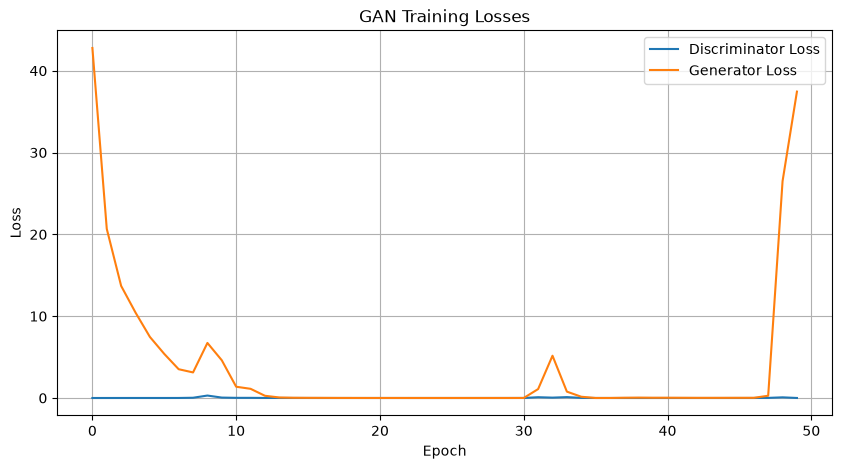

In [ ]:
# ==========================================
# 5.10 PLOT GAN TRAINING LOSSES
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(d_losses_v2, label="Discriminator Loss")
plt.plot(g_losses_v2, label="Generator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Losses")
plt.legend()
plt.grid(True)

plt.show()

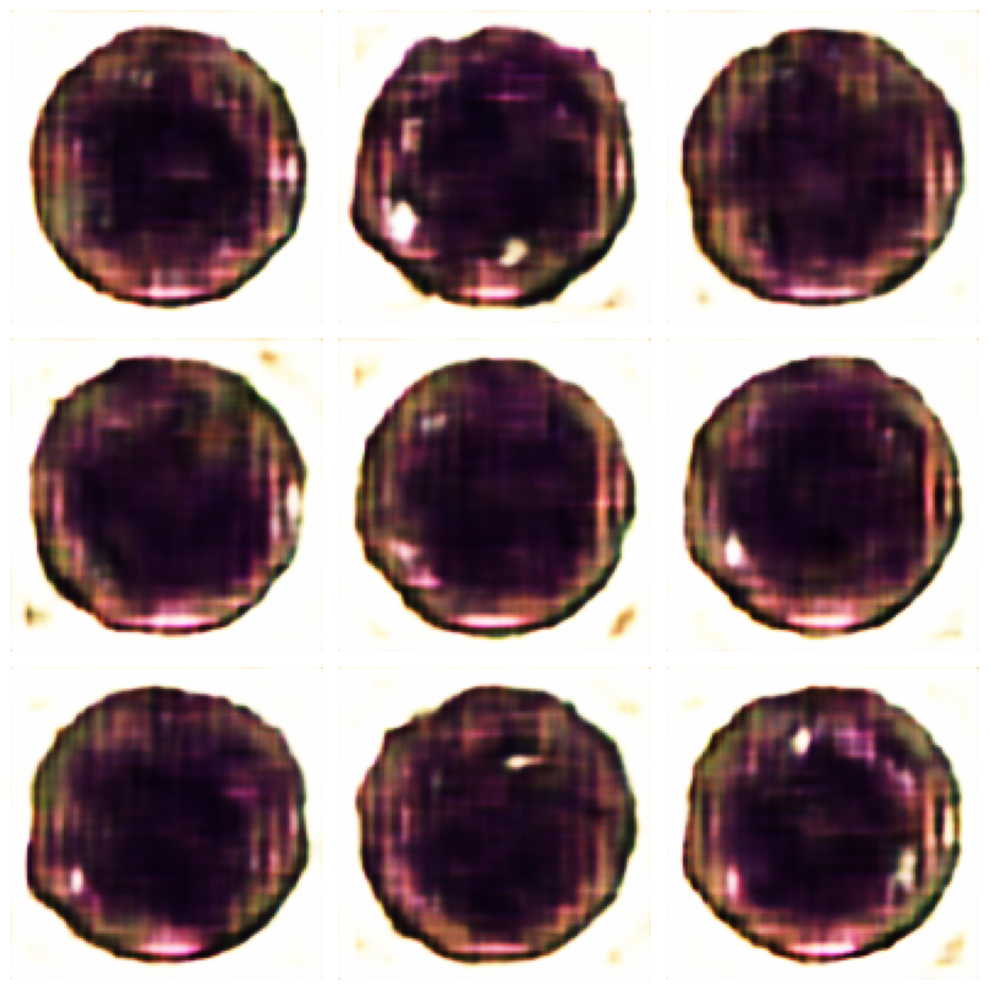

In [ ]:
# ==========================================
# 5.11 VISUALIZE FINAL GENERATOR V2 OUTPUTS
# ==========================================

generated_images_v2 = generator_v2(
    FIXED_Z_V2,
    training=False
)

plt.figure(figsize=(10, 10))

for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(generated_images_v2[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

### Discussion — Generator V2

The second Generator architecture replaced transposed convolutions with nearest-neighbor upsampling followed by standard convolutions. This design separates spatial resolution increases from feature extraction and may reduce checkerboard artifacts associated with some transposed-convolution configurations.

The generated samples showed recognizable circular structures, but noticeable color differences, blurred details, and residual visual artifacts remained. The revised architecture also substantially increased the number of parameters in the initial dense projection, introducing a potential computational cost.

The comparison remains preliminary because Generator V2 reused the Discriminator from the previous experiment. Consequently, the observed differences cannot be attributed exclusively to the Generator architecture. A controlled experiment with independently initialized models and verified parameter updates is required before drawing conclusions about the effectiveness of the revised design.


In [ ]:
# ==========================================
# 5.8 BUILD AN INDEPENDENT DISCRIMINATOR V2
# ==========================================

discriminator_v2 = models.Sequential(name="Discriminator_V2")

discriminator_v2.add(
    layers.Input(shape=(*IMG_SIZE, CHANNELS))
)

# Feature extraction
discriminator_v2.add(
    layers.Conv2D(32, kernel_size=4, strides=2, padding="same")
)
discriminator_v2.add(layers.LeakyReLU(negative_slope=0.2))

discriminator_v2.add(
    layers.Conv2D(64, kernel_size=4, strides=2, padding="same")
)
discriminator_v2.add(layers.BatchNormalization())
discriminator_v2.add(layers.LeakyReLU(negative_slope=0.2))

discriminator_v2.add(
    layers.Conv2D(128, kernel_size=4, strides=2, padding="same")
)
discriminator_v2.add(layers.BatchNormalization())
discriminator_v2.add(layers.LeakyReLU(negative_slope=0.2))

# Binary classification
discriminator_v2.add(layers.Flatten())
discriminator_v2.add(layers.Dense(1, activation="sigmoid"))

# Compile independently before connecting it to the GAN
discriminator_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0002
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

discriminator_v2.summary()


Model: "Discriminator_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 64, 64, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │        32,769 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 199,137 (777.88 KB)

 Trainable params: 198,753 (776.38 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
# ==========================================
# 5.9 CONNECT GENERATOR V2 WITH DISCRIMINATOR V2
# ==========================================

# Freeze the independent Discriminator during Generator updates
discriminator_v2.trainable = False

gan_v2 = models.Sequential(
    [
        generator_v2,
        discriminator_v2
    ],
    name="GAN_V2"
)

gan_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0002
    ),
    loss="binary_crossentropy"
)

gan_v2.summary()

# Verify output shape
z = tf.random.normal((1, LATENT_DIM))
gan_output_v2 = gan_v2(z, training=False)

print("Latent vector shape:", z.shape)
print("GAN V2 output shape:", gan_output_v2.shape)
print("Discriminator score:", float(gan_output_v2[0, 0]))


Model: "GAN_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Generator_V2 (Sequential)       │ (None, 128, 128, 3)    │     5,797,059 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator_V2 (Sequential)   │ (None, 1)              │       199,137 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,996,196 (22.87 MB)

 Trainable params: 5,796,099 (22.11 MB)

 Non-trainable params: 200,097 (781.63 KB)

Latent vector shape: (1, 128)
GAN V2 output shape: (1, 1)
Discriminator score: 0.5009135603904724


Latent vector shape: (1, 128)
Generated image shape: (1, 128, 128, 3)
GAN V2 output shape: (1, 1)
Discriminator score: 0.5006145238876343


I0000 00:00:1792079094.184369   71464 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_468968__XlaMustCompile_true_config_proto_2201667018877855759_executor_type_11160318154034397263_.41


Epoch 01/100 | D Loss: 0.1850 | D Acc: 0.8817 | G Loss: 0.6590
Epoch 02/100 | D Loss: 0.0285 | D Acc: 0.9978 | G Loss: 0.5069
Epoch 03/100 | D Loss: 0.0346 | D Acc: 0.9978 | G Loss: 0.3748
Epoch 04/100 | D Loss: 0.0254 | D Acc: 0.9978 | G Loss: 0.3542
Epoch 05/100 | D Loss: 0.0488 | D Acc: 0.9978 | G Loss: 0.4462
Epoch 06/100 | D Loss: 0.0058 | D Acc: 0.9978 | G Loss: 0.2762
Epoch 07/100 | D Loss: 0.0004 | D Acc: 1.0000 | G Loss: 0.1625
Epoch 08/100 | D Loss: 0.0009 | D Acc: 1.0000 | G Loss: 0.0948
Epoch 09/100 | D Loss: 0.0009 | D Acc: 1.0000 | G Loss: 0.0577
Epoch 10/100 | D Loss: 0.0012 | D Acc: 1.0000 | G Loss: 0.0327
Epoch 11/100 | D Loss: 0.0010 | D Acc: 1.0000 | G Loss: 0.0183
Epoch 12/100 | D Loss: 0.0012 | D Acc: 1.0000 | G Loss: 0.0098
Epoch 13/100 | D Loss: 0.0015 | D Acc: 1.0000 | G Loss: 0.0054
Epoch 14/100 | D Loss: 0.0013 | D Acc: 1.0000 | G Loss: 0.0030
Epoch 15/100 | D Loss: 0.0009 | D Acc: 1.0000 | G Loss: 0.0018
Epoch 16/100 | D Loss: 0.0007 | D Acc: 1.0000 | G Loss:

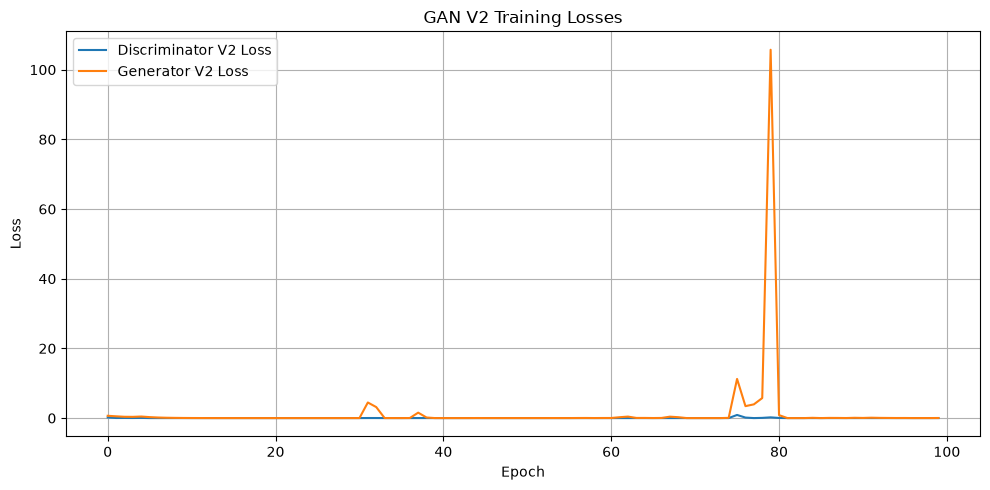

<module 'matplotlib.pyplot' from '/home/maritza/projects/computer_vision/.venv/lib/python3.12/site-packages/matplotlib/pyplot.py'>

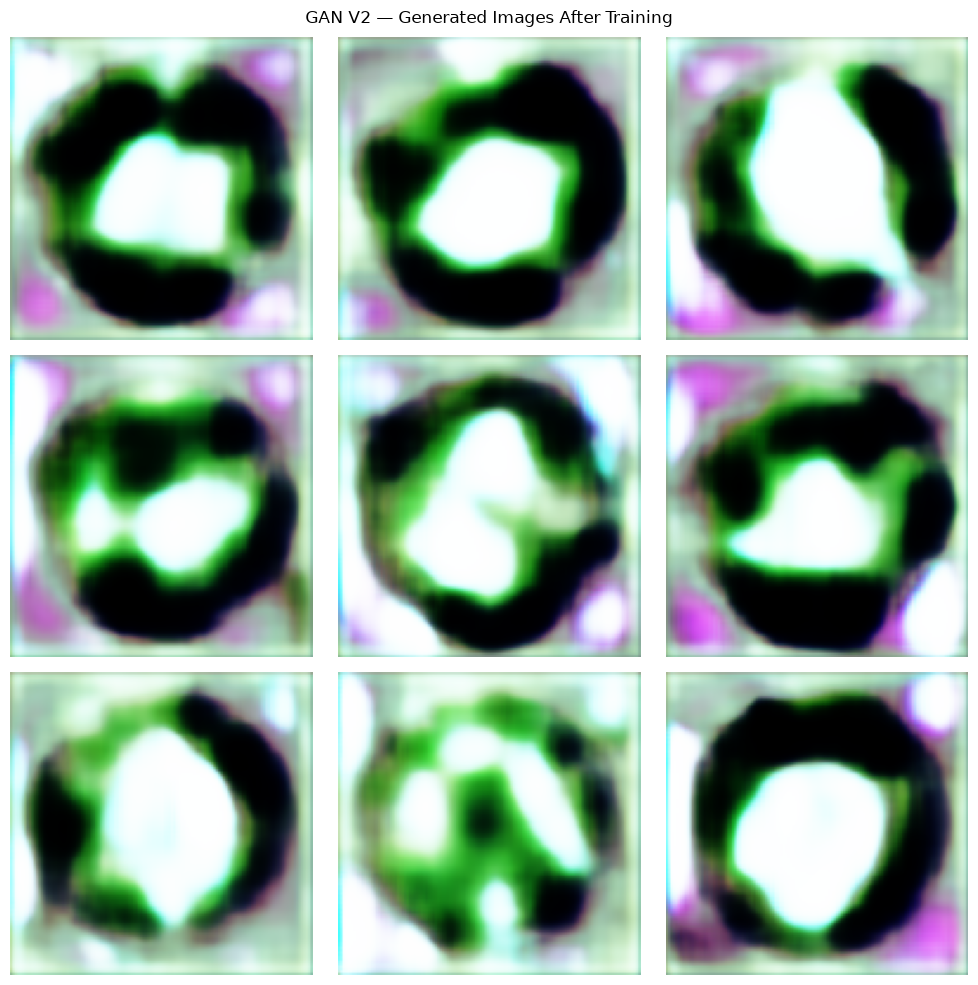

In [ ]:
# ==========================================
# 5.10 VERIFY GAN V2 OUTPUT
# ==========================================

z = tf.random.normal((1, LATENT_DIM))
gan_output_v2 = gan_v2(z, training=False)

print("Latent vector shape:", z.shape)
print("Generated image shape:", generator_v2(z, training=False).shape)
print("GAN V2 output shape:", gan_output_v2.shape)
print("Discriminator score:", float(gan_output_v2[0, 0]))


# ==========================================
# 5.11 TRAIN GAN V2
# ==========================================

EPOCHS_V2 = 100

d_losses_v2 = []
d_accuracies_v2 = []
g_losses_v2 = []

FIXED_Z_V2 = tf.random.normal((9, LATENT_DIM))

for epoch in range(EPOCHS_V2):

    epoch_d_losses = []
    epoch_d_accuracies = []
    epoch_g_losses = []

    for real_images in train_dataset:

        current_batch_size = tf.shape(real_images)[0]

        # ------------------------------------------
        # Train Discriminator V2
        # ------------------------------------------

        # Enable Discriminator updates
        discriminator_v2.trainable = True

        # Generate fake images
        z = tf.random.normal((current_batch_size, LATENT_DIM))
        fake_images = generator_v2(z, training=False)

        # Create real and fake labels
        real_labels = tf.ones((current_batch_size, 1))
        fake_labels = tf.zeros((current_batch_size, 1))

        # Combine real and fake samples
        combined_images = tf.concat(
            [real_images, fake_images],
            axis=0
        )
        combined_labels = tf.concat(
            [real_labels, fake_labels],
            axis=0
        )

        # Update Discriminator weights directly
        d_loss, d_accuracy = discriminator_v2.train_on_batch(
            combined_images,
            combined_labels
        )

        # ------------------------------------------
        # Train Generator V2
        # ------------------------------------------

        # Freeze Discriminator for Generator optimization
        discriminator_v2.trainable = False

        z = tf.random.normal((current_batch_size, LATENT_DIM))
        generator_targets = tf.ones((current_batch_size, 1))

        # Update Generator through the combined GAN
        g_loss = gan_v2.train_on_batch(
            z,
            generator_targets
        )

        epoch_d_losses.append(float(d_loss))
        epoch_d_accuracies.append(float(d_accuracy))
        epoch_g_losses.append(float(g_loss))

    # Average metrics across batches
    mean_d_loss = np.mean(epoch_d_losses)
    mean_d_accuracy = np.mean(epoch_d_accuracies)
    mean_g_loss = np.mean(epoch_g_losses)

    d_losses_v2.append(mean_d_loss)
    d_accuracies_v2.append(mean_d_accuracy)
    g_losses_v2.append(mean_g_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS_V2} | "
        f"D Loss: {mean_d_loss:.4f} | "
        f"D Acc: {mean_d_accuracy:.4f} | "
        f"G Loss: {mean_g_loss:.4f}"
    )


# ==========================================
# 5.12 PLOT TRAINING LOSSES
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(d_losses_v2, label="Discriminator V2 Loss")
plt.plot(g_losses_v2, label="Generator V2 Loss")

plt.title("GAN V2 Training Losses")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# 5.13 VISUALIZE FINAL GENERATOR V2 OUTPUTS
# ==========================================

generated_images_v2 = generator_v2(
    FIXED_Z_V2,
    training=False
)

plt.figure(figsize=(10, 10))

for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(np.clip(generated_images_v2[i].numpy(), 0, 1))
    plt.axis("off")

plt.suptitle("GAN V2 — Generated Images After Training")
plt.tight_layout()
plt

Epochs: 50
Learning rate: 0.0001
Generator: Generator_V2


Model: "Discriminator_V3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 64, 64, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │        32,769 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 199,137 (777.88 KB)

 Trainable params: 198,753 (776.38 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 01/50 | D Loss: 0.3382 | D Accuracy: 0.9196 | G Loss: 0.7366
Epoch 02/50 | D Loss: 0.0675 | D Accuracy: 1.0000 | G Loss: 0.7490
Epoch 03/50 | D Loss: 0.0487 | D Accuracy: 1.0000 | G Loss: 0.8155
Epoch 04/50 | D Loss: 0.0371 | D Accuracy: 1.0000 | G Loss: 0.9278
Epoch 05/50 | D Loss: 0.0165 | D Accuracy: 1.0000 | G Loss: 0.9355
Epoch 06/50 | D Loss: 0.0123 | D Accuracy: 1.0000 | G Loss: 0.7191
Epoch 07/50 | D Loss: 0.0069 | D Accuracy: 1.0000 | G Loss: 0.5579
Epoch 08/50 | D Loss: 0.0056 | D Accuracy: 1.0000 | G Loss: 0.3506
Epoch 09/50 | D Loss: 0.0052 | D Accuracy: 1.0000 | G Loss: 0.2281
Epoch 10/50 | D Loss: 0.0053 | D Accuracy: 1.0000 | G Loss: 0.1723
Epoch 11/50 | D Loss: 0.0051 | D Accuracy: 1.0000 | G Loss: 0.1176
Epoch 12/50 | D Loss: 0.0042 | D Accuracy: 1.0000 | G Loss: 0.0989
Epoch 13/50 | D Loss: 0.0050 | D Accuracy: 1.0000 | G Loss: 0.0833
Epoch 14/50 | D Loss: 0.0032 | D Accuracy: 1.0000 | G Loss: 0.0451
Epoch 15/50 | D Loss: 0.0033 | D Accuracy: 1.0000 | G Loss: 0.

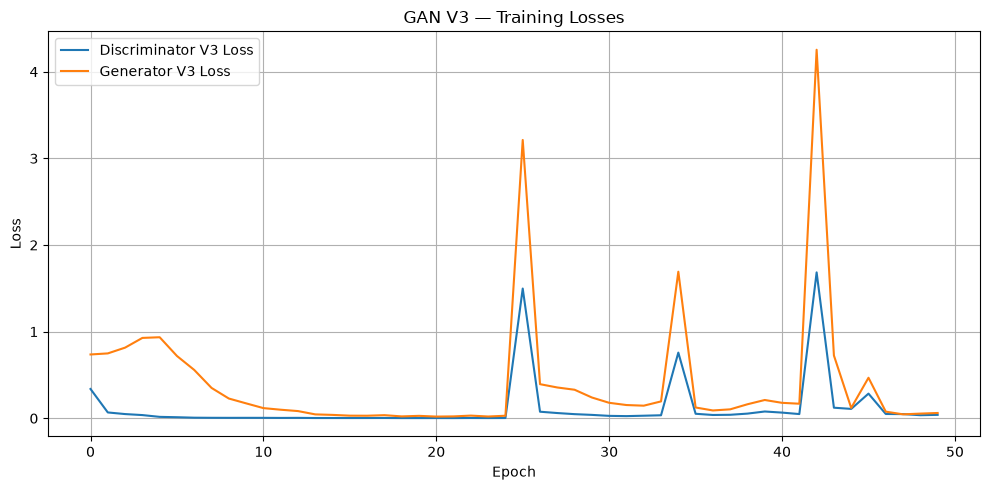

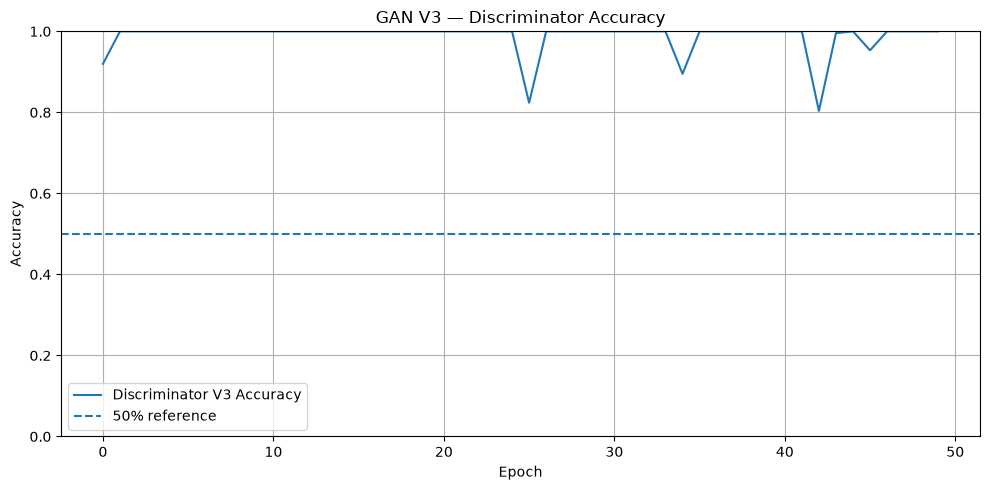

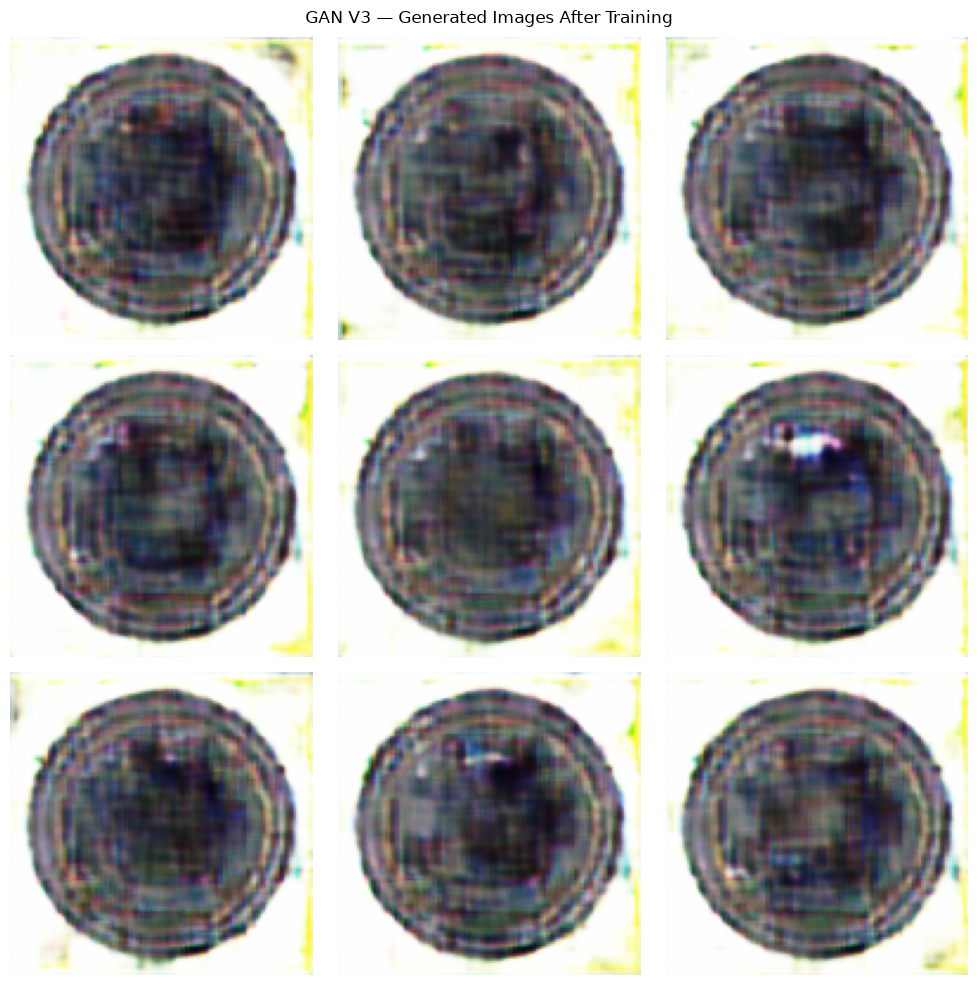

In [ ]:
# ==========================================
# 5.14 CONTROLLED GAN V3 TRAINING
# ==========================================

# This experiment keeps Generator V2's architecture
# and uses a new, independently initialized Discriminator.

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------
# Training configuration
# ------------------------------------------

EPOCHS_V3 = 50
LEARNING_RATE_V3 = 0.0001

# Reproducible latent vectors for visual monitoring
tf.random.set_seed(42)
FIXED_Z_V3 = tf.random.normal((9, LATENT_DIM))

# Store training history
d_losses_v3 = []
d_accuracies_v3 = []
g_losses_v3 = []

print("Epochs:", EPOCHS_V3)
print("Learning rate:", LEARNING_RATE_V3)
print("Generator:", generator_v2.name)


# ==========================================
# 5.15 BUILD AN INDEPENDENT DISCRIMINATOR V3
# ==========================================

discriminator_v3 = tf.keras.Sequential(
    [
        layers.Input(shape=(*IMG_SIZE, CHANNELS)),

        layers.Conv2D(
            32, kernel_size=4, strides=2, padding="same"
        ),
        layers.LeakyReLU(negative_slope=0.2),

        layers.Conv2D(
            64, kernel_size=4, strides=2, padding="same"
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(negative_slope=0.2),

        layers.Conv2D(
            128, kernel_size=4, strides=2, padding="same"
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(negative_slope=0.2),

        layers.Flatten(),
        layers.Dense(1, activation="sigmoid")
    ],
    name="Discriminator_V3"
)

discriminator_v3.summary()


# ==========================================
# 5.16 DEFINE OPTIMIZERS AND LOSS FUNCTION
# ==========================================

d_optimizer_v3 = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE_V3,
    beta_1=0.5
)

g_optimizer_v3 = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE_V3,
    beta_1=0.5
)

binary_cross_entropy = tf.keras.losses.BinaryCrossentropy()

# Discriminator loss for real and fake images
def discriminator_loss_v3(real_predictions, fake_predictions):
    real_loss = binary_cross_entropy(
        tf.ones_like(real_predictions),
        real_predictions
    )

    fake_loss = binary_cross_entropy(
        tf.zeros_like(fake_predictions),
        fake_predictions
    )

    return real_loss + fake_loss


# Generator loss: generated images should be classified as real
def generator_loss_v3(fake_predictions):
    return binary_cross_entropy(
        tf.ones_like(fake_predictions),
        fake_predictions
    )


# Explicitly build optimizer variables before training
# so that optimizer state is initialized consistently.
_ = discriminator_v3(
    tf.zeros((1, *IMG_SIZE, CHANNELS)),
    training=False
)

_ = generator_v2(
    tf.zeros((1, LATENT_DIM)),
    training=False
)

d_optimizer_v3.build(discriminator_v3.trainable_variables)
g_optimizer_v3.build(generator_v2.trainable_variables)


# ==========================================
# 5.17 DEFINE EXPLICIT TRAINING STEPS
# ==========================================

@tf.function
def train_step_v3(real_images):

    batch_size = tf.shape(real_images)[0]

    # ------------------------------------------
    # Train Discriminator
    # ------------------------------------------

    noise = tf.random.normal((batch_size, LATENT_DIM))

    # Generate fake images without updating Generator weights
    fake_images = generator_v2(noise, training=False)
    fake_images = tf.stop_gradient(fake_images)

    with tf.GradientTape() as d_tape:

        real_predictions = discriminator_v3(
            real_images,
            training=True
        )

        fake_predictions = discriminator_v3(
            fake_images,
            training=True
        )

        d_loss = discriminator_loss_v3(
            real_predictions,
            fake_predictions
        )

    d_gradients = d_tape.gradient(
        d_loss,
        discriminator_v3.trainable_variables
    )

    d_optimizer_v3.apply_gradients(
        (gradient, variable)
        for gradient, variable in zip(
            d_gradients,
            discriminator_v3.trainable_variables
        )
        if gradient is not None
    )

    # ------------------------------------------
    # Train Generator
    # ------------------------------------------

    noise = tf.random.normal((batch_size, LATENT_DIM))

    with tf.GradientTape() as g_tape:

        generated_images = generator_v2(
            noise,
            training=True
        )

        # Discriminator weights are not updated here.
        # Gradients still flow through D to the Generator.
        fake_predictions_for_g = discriminator_v3(
            generated_images,
            training=False
        )

        g_loss = generator_loss_v3(
            fake_predictions_for_g
        )

    g_gradients = g_tape.gradient(
        g_loss,
        generator_v2.trainable_variables
    )

    g_optimizer_v3.apply_gradients(
        (gradient, variable)
        for gradient, variable in zip(
            g_gradients,
            generator_v2.trainable_variables
        )
        if gradient is not None
    )

    # Discriminator accuracy using a 0.5 decision threshold
    real_accuracy = tf.reduce_mean(
        tf.cast(real_predictions >= 0.5, tf.float32)
    )

    fake_accuracy = tf.reduce_mean(
        tf.cast(fake_predictions < 0.5, tf.float32)
    )

    d_accuracy = 0.5 * (real_accuracy + fake_accuracy)

    return d_loss, d_accuracy, g_loss


# ==========================================
# 5.18 TRAIN GAN V3
# ==========================================

# Save initial weights to verify that training changes them.
initial_g_weights = [
    variable.numpy().copy()
    for variable in generator_v2.trainable_variables
]

initial_d_weights = [
    variable.numpy().copy()
    for variable in discriminator_v3.trainable_variables
]

for epoch in range(EPOCHS_V3):

    epoch_d_losses = []
    epoch_d_accuracies = []
    epoch_g_losses = []

    for real_images in train_dataset:

        real_images = tf.cast(real_images, tf.float32)

        d_loss, d_accuracy, g_loss = train_step_v3(real_images)

        epoch_d_losses.append(float(d_loss.numpy()))
        epoch_d_accuracies.append(float(d_accuracy.numpy()))
        epoch_g_losses.append(float(g_loss.numpy()))

    mean_d_loss = float(np.mean(epoch_d_losses))
    mean_d_accuracy = float(np.mean(epoch_d_accuracies))
    mean_g_loss = float(np.mean(epoch_g_losses))

    d_losses_v3.append(mean_d_loss)
    d_accuracies_v3.append(mean_d_accuracy)
    g_losses_v3.append(mean_g_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS_V3} | "
        f"D Loss: {mean_d_loss:.4f} | "
        f"D Accuracy: {mean_d_accuracy:.4f} | "
        f"G Loss: {mean_g_loss:.4f}"
    )


# ==========================================
# 5.19 VERIFY THAT BOTH NETWORKS WERE UPDATED
# ==========================================

g_weight_changes = [
    np.mean(np.abs(variable.numpy() - initial))
    for variable, initial in zip(
        generator_v2.trainable_variables,
        initial_g_weights
    )
]

d_weight_changes = [
    np.mean(np.abs(variable.numpy() - initial))
    for variable, initial in zip(
        discriminator_v3.trainable_variables,
        initial_d_weights
    )
]

print("\nTRAINING UPDATE CHECK")
print("-" * 40)
print(
    "Generator mean absolute weight change:",
    f"{np.mean(g_weight_changes):.8f}"
)
print(
    "Discriminator mean absolute weight change:",
    f"{np.mean(d_weight_changes):.8f}"
)


# ==========================================
# 5.20 PLOT TRAINING LOSSES
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(d_losses_v3, label="Discriminator V3 Loss")
plt.plot(g_losses_v3, label="Generator V3 Loss")

plt.title("GAN V3 — Training Losses")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# 5.21 PLOT DISCRIMINATOR ACCURACY
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    d_accuracies_v3,
    label="Discriminator V3 Accuracy"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="50% reference"
)

plt.title("GAN V3 — Discriminator Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# 5.22 VISUALIZE GENERATED IMAGES
# ==========================================

generated_images_v3 = generator_v2(
    FIXED_Z_V3,
    training=False
)

plt.figure(figsize=(10, 10))

for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    ax.imshow(
        np.clip(generated_images_v3[i].numpy(), 0, 1)
    )
    ax.axis("off")

plt.suptitle("GAN V3 — Generated Images After Training")
plt.tight_layout()
plt.show()


In [ ]:
# ==========================================
# 6.1 LOAD TEST IMAGES AND LABELS
# ==========================================

from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

DATA_DIR = Path("bottle")
TEST_DIR = DATA_DIR / "test"

IMG_SIZE = (128, 128)
CHANNELS = 3
BATCH_SIZE = 16

test_paths = []
test_labels = []
test_categories = []

if not TEST_DIR.exists():
    raise FileNotFoundError(
        f"Test directory not found: {TEST_DIR.resolve()}"
    )

for category_dir in sorted(TEST_DIR.iterdir()):

    if not category_dir.is_dir():
        continue

    category = category_dir.name

    for image_path in sorted(category_dir.glob("*.png")):
        test_paths.append(str(image_path))
        test_labels.append(0 if category == "good" else 1)
        test_categories.append(category)

if not test_paths:
    raise RuntimeError(
        f"No PNG test images found in {TEST_DIR.resolve()}"
    )


# Load and preprocess images
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    color_mode="rgb"
)

def normalize_test_images(images):
    return tf.cast(images, tf.float32) / 255.0

test_dataset = test_dataset.map(
    normalize_test_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)


# Dataset summary
print("Test directory:", TEST_DIR.resolve())
print("Total test images:", len(test_paths))
print("Normal images:", test_labels.count(0))
print("Anomalous images:", test_labels.count(1))

print("\nImages by category:")
for category, count in sorted(Counter(test_categories).items()):
    print(f"{category:25s}: {count}")

# Verify the batch shape
for images in test_dataset.take(1):
    print("\nBatch shape:", images.shape)
    print("Pixel range:", float(tf.reduce_min(images)),
          "to", float(tf.reduce_max(images)))


# ==========================================
# 6.2 PREPARE THE EVALUATION DATASET
# ==========================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

DATA_DIR = Path("bottle")
TEST_DIR = DATA_DIR / "test"
IMG_SIZE = (128, 128)
CHANNELS = 3

test_paths = []
test_labels = []
test_categories = []

for category_dir in sorted(TEST_DIR.iterdir()):
    if not category_dir.is_dir():
        continue

    category = category_dir.name

    for image_path in sorted(category_dir.glob("*.png")):
        test_paths.append(str(image_path))
        test_labels.append(0 if category == "good" else 1)
        test_categories.append(category)

test_labels = np.asarray(test_labels, dtype=np.int32)
test_categories = np.asarray(test_categories)

def load_test_image(path):
    image = tf.io.read_file(path)
    image = tf.io.decode_png(image, channels=CHANNELS)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image

test_images = tf.stack([
    load_test_image(path) for path in test_paths
])

print("Test images:", len(test_paths))
print("Image tensor:", test_images.shape)
print("Normal images:", int(np.sum(test_labels == 0)))
print("Anomalous images:", int(np.sum(test_labels == 1)))
print("Pixel range:",
      float(tf.reduce_min(test_images)),
      "to",
      float(tf.reduce_max(test_images)))


# ==========================================
# 6.3 SELECT THE GENERATOR
# ==========================================

# Current generator_v2 may contain the weights updated during V3 training.
generator_eval = generator_v2

LATENT_DIM = 128

# Use a fixed random seed for reproducibility.
tf.random.set_seed(42)

# Verify the generator output shape.
z_check = tf.random.normal((2, LATENT_DIM))
generated_check = generator_eval(z_check, training=False)

print("Latent input shape:", z_check.shape)
print("Generator output shape:", generated_check.shape)
print("Generator parameters:", generator_eval.count_params())

assert tuple(generated_check.shape[1:]) == (128, 128, 3), (
    "The generator output must have shape (128, 128, 3)."
)







Found 83 files.
Test directory: /home/maritza/projects/computer_vision_labs/GANsvg/bottle/test
Total test images: 83
Normal images: 20
Anomalous images: 63

Images by category:
broken_large             : 20
broken_small             : 22
contamination            : 21
good                     : 20

Batch shape: (16, 128, 128, 3)
Pixel range: 0.10588235408067703 to 1.0
Test images: 83
Image tensor: (83, 128, 128, 3)
Normal images: 20
Anomalous images: 63
Pixel range: 0.09907513856887817 to 1.0
Latent input shape: (2, 128)
Generator output shape: (2, 128, 128, 3)
Generator parameters: 5797059


In [ ]:

# ==========================================
# 6.4 LATENT OPTIMIZATION ANOMALY SCORE
# ==========================================

LATENT_DIM = 128
LATENT_STEPS = 300
LATENT_LR = 0.03

# Weight initialization is reproducible.
latent_rng = tf.random.Generator.from_seed(1234)

def calculate_anomaly_score(
    image,
    generator,
    steps=LATENT_STEPS,
    learning_rate=LATENT_LR
):
    """
    Optimize a latent vector to approximate one image.

    Returns:
        score: final mean absolute reconstruction error
        reconstruction: generated approximation of the image
    """

    image = tf.cast(image, tf.float32)
    image_batch = image[tf.newaxis, ...]

    # Optimize only z; generator weights remain unchanged.
    z = tf.Variable(
        latent_rng.normal(shape=(1, LATENT_DIM)),
        trainable=True,
        dtype=tf.float32
    )

    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

    for _ in range(steps):
        with tf.GradientTape() as tape:
            reconstruction = generator(z, training=False)
            loss = tf.reduce_mean(
                tf.abs(image_batch - reconstruction)
            )

        gradients = tape.gradient(loss, [z])
        optimizer.apply_gradients(zip(gradients, [z]))

    reconstruction = generator(z, training=False)
    score = tf.reduce_mean(
        tf.abs(image_batch - reconstruction)
    )

    return float(score.numpy()), reconstruction[0].numpy()


# Quick pilot run on one image before processing the entire test set.
pilot_score, pilot_reconstruction = calculate_anomaly_score(
    test_images[0],
    generator_eval,
    steps=50
)

print("Pilot reconstruction score:", pilot_score)
print("Pilot reconstruction shape:", pilot_reconstruction.shape)


# ==========================================
# 6.5 SCORE ALL TEST IMAGES
# ==========================================

LATENT_STEPS = 300

anomaly_scores = []
reconstructions = []

for index in range(len(test_images)):
    score, reconstruction = calculate_anomaly_score(
        test_images[index],
        generator_eval,
        steps=LATENT_STEPS
    )

    anomaly_scores.append(score)
    reconstructions.append(reconstruction)

    if (index + 1) % 5 == 0 or index + 1 == len(test_images):
        print(
            f"Processed {index + 1}/{len(test_images)} images "
            f"| latest score: {score:.5f}"
        )

anomaly_scores = np.asarray(anomaly_scores, dtype=np.float32)
reconstructions = np.asarray(reconstructions, dtype=np.float32)

print("\nEvaluation complete.")
print("Scores shape:", anomaly_scores.shape)
print("Reconstructions shape:", reconstructions.shape)
print("Minimum score:", float(anomaly_scores.min()))
print("Maximum score:", float(anomaly_scores.max()))
print("Mean score:", float(anomaly_scores.mean()))



# ==========================================
# 6.6 VISUALIZE RECONSTRUCTIONS
# ==========================================

def show_reconstruction_examples(
    labels,
    categories,
    scores,
    images,
    reconstructions,
    examples_per_group=4
):
    normal_indices = np.where(labels == 0)[0][:examples_per_group]
    anomaly_indices = np.where(labels == 1)[0][:examples_per_group]

    selected_indices = list(normal_indices) + list(anomaly_indices)

    fig, axes = plt.subplots(
        len(selected_indices), 3,
        figsize=(10, 3.2 * len(selected_indices))
    )

    if len(selected_indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, index in enumerate(selected_indices):
        axes[row, 0].imshow(images[index].numpy())
        axes[row, 0].set_title(
            f"Original\n{categories[index]}"
        )

        axes[row, 1].imshow(
            np.clip(reconstructions[index], 0, 1)
        )
        axes[row, 1].set_title("GAN reconstruction")

        difference = np.mean(
            np.abs(images[index].numpy() - reconstructions[index]),
            axis=-1
        )
        axes[row, 2].imshow(difference, cmap="inferno")
        axes[row, 2].set_title(
            f"Absolute error\nScore: {scores[index]:.4f}"
        )

        for ax in axes[row]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


show_reconstruction_examples(
    test_labels,
    test_categories,
    anomaly_scores,
    test_images,
    reconstructions,
    examples_per_group=4
)



# ==========================================
# 6.7 ANOMALY SCORE DISTRIBUTIONS
# ==========================================

normal_scores = anomaly_scores[test_labels == 0]
anomalous_scores = anomaly_scores[test_labels == 1]

plt.figure(figsize=(9, 5))

plt.hist(
    normal_scores,
    bins=12,
    alpha=0.65,
    label="Good / normal"
)
plt.hist(
    anomalous_scores,
    bins=12,
    alpha=0.65,
    label="Defective / anomalous"
)

plt.xlabel("Mean absolute reconstruction error")
plt.ylabel("Number of images")
plt.title("Anomaly score distributions")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Normal images:")
print("  Mean:", float(normal_scores.mean()))
print("  Std:", float(normal_scores.std()))
print("  Median:", float(np.median(normal_scores)))

print("\nAnomalous images:")
print("  Mean:", float(anomalous_scores.mean()))
print("  Std:", float(anomalous_scores.std()))
print("  Median:", float(np.median(anomalous_scores)))



NameError: name 'tf' is not defined

Threshold-independent metrics
------------------------------
ROC-AUC:           0.6794
Average Precision: 0.8743

Exploratory threshold: 0.15567278861999512

Threshold-dependent metrics
---------------------------
Accuracy:  0.4699
Precision: 0.9524
Recall:    0.3175
F1-score:  0.4762

Confusion matrix (rows=true, columns=predicted)
Order: [normal, anomalous]
[[19  1]
 [43 20]]

Classification report
              precision    recall  f1-score   support

      normal       0.31      0.95      0.46        20
   anomalous       0.95      0.32      0.48        63

    accuracy                           0.47        83
   macro avg       0.63      0.63      0.47        83
weighted avg       0.80      0.47      0.47        83



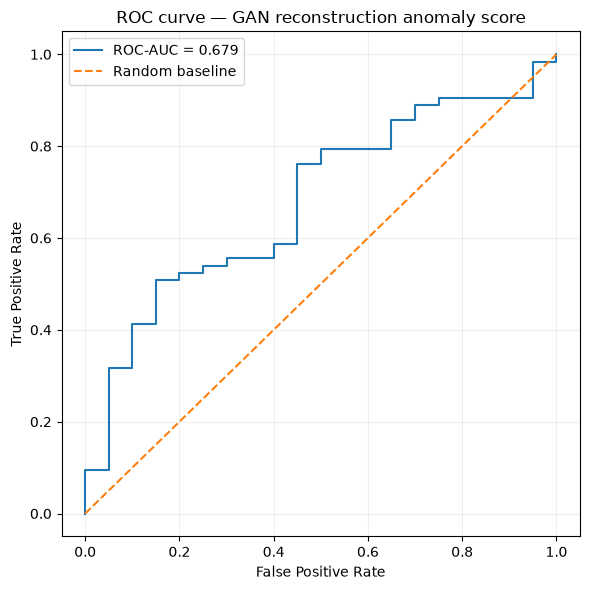

broken_large       | n=20 | mean=0.15506 | median=0.15440 | std=0.00319
broken_small       | n=22 | mean=0.15341 | median=0.15292 | std=0.00236
contamination      | n=21 | mean=0.15560 | median=0.15522 | std=0.00310
good               | n=20 | mean=0.15304 | median=0.15239 | std=0.00183


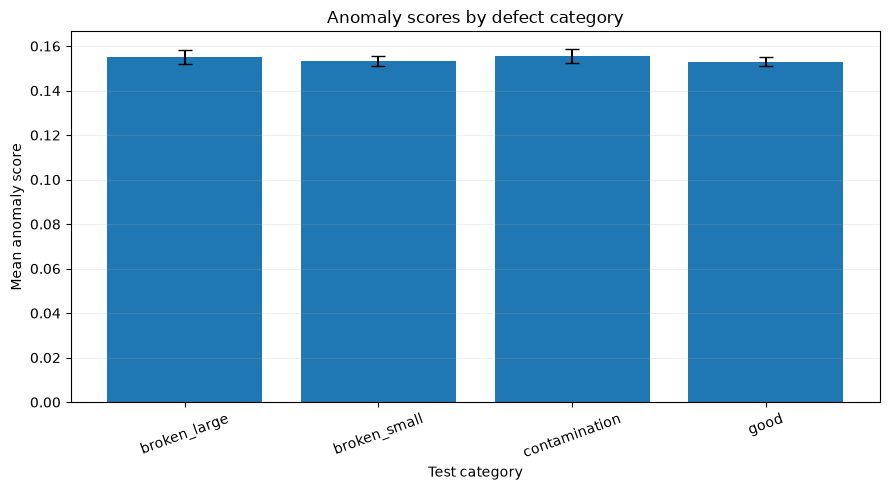

Saved:
 - gan_anomaly_evaluation.csv
 - gan_anomaly_scores.npy
 - gan_reconstructions.npy


In [ ]:

# ==========================================
# 6.8 ANOMALY DETECTION METRICS
# ==========================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_curve
)

# Scores should be higher for anomalous images.
roc_auc = roc_auc_score(test_labels, anomaly_scores)
average_precision = average_precision_score(
    test_labels,
    anomaly_scores
)

print("Threshold-independent metrics")
print("------------------------------")
print(f"ROC-AUC:           {roc_auc:.4f}")
print(f"Average Precision: {average_precision:.4f}")

# Exploratory threshold: 95th percentile of NORMAL test scores.
threshold = float(np.percentile(normal_scores, 95))

predicted_labels = (anomaly_scores > threshold).astype(np.int32)

print("\nExploratory threshold:", threshold)
print("\nThreshold-dependent metrics")
print("---------------------------")
print(f"Accuracy:  {accuracy_score(test_labels, predicted_labels):.4f}")
print(f"Precision: {precision_score(test_labels, predicted_labels, zero_division=0):.4f}")
print(f"Recall:    {recall_score(test_labels, predicted_labels, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(test_labels, predicted_labels, zero_division=0):.4f}")

cm = confusion_matrix(
    test_labels,
    predicted_labels,
    labels=[0, 1]
)

print("\nConfusion matrix (rows=true, columns=predicted)")
print("Order: [normal, anomalous]")
print(cm)

print("\nClassification report")
print(classification_report(
    test_labels,
    predicted_labels,
    labels=[0, 1],
    target_names=["normal", "anomalous"],
    zero_division=0
))

fpr, tpr, thresholds = roc_curve(test_labels, anomaly_scores)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve — GAN reconstruction anomaly score")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# ==========================================
# 6.9 SCORES BY CATEGORY
# ==========================================

categories_unique = sorted(np.unique(test_categories))

category_means = []
category_stds = []
category_counts = []

for category in categories_unique:
    category_mask = test_categories == category
    category_category_scores = anomaly_scores[category_mask]

    category_means.append(float(category_category_scores.mean()))
    category_stds.append(float(category_category_scores.std()))
    category_counts.append(int(category_mask.sum()))

    print(
        f"{category:18s} | "
        f"n={category_mask.sum():2d} | "
        f"mean={category_category_scores.mean():.5f} | "
        f"median={np.median(category_category_scores):.5f} | "
        f"std={category_category_scores.std():.5f}"
    )

plt.figure(figsize=(9, 5))
plt.bar(
    categories_unique,
    category_means,
    yerr=category_stds,
    capsize=5
)
plt.ylabel("Mean anomaly score")
plt.xlabel("Test category")
plt.title("Anomaly scores by defect category")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()



# ==========================================
# 6.10 SAVE EVALUATION RESULTS
# ==========================================

import pandas as pd

results_df = pd.DataFrame({
    "image_path": test_paths,
    "category": test_categories,
    "true_label": test_labels,
    "anomaly_score": anomaly_scores,
    "predicted_label": predicted_labels
})

results_df.to_csv("gan_anomaly_evaluation.csv", index=False)
np.save("gan_anomaly_scores.npy", anomaly_scores)
np.save("gan_reconstructions.npy", reconstructions)

print("Saved:")
print(" - gan_anomaly_evaluation.csv")
print(" - gan_anomaly_scores.npy")
print(" - gan_reconstructions.npy")

